# Atención espacial (SAM): ¿contenido o posición?

El SAM del paper (ec. 2) calcula una máscara con una convolución 7×7 sobre el
promedio y el máximo por canal del feature map de ResNet-50. Con imágenes de
128×64 ese mapa mide **8×4**: el kernel 7×7 es más grande que el mapa y gran
parte de lo que ve es el padding de ceros.

Pregunta: la máscara aprendida, ¿separa a la persona del fondo (contenido) o
depende sobre todo de la posición de cada celda dentro del mapa?

Pruebas:

1. **Geometría.** Qué fracción del kernel cae sobre padding en cada posición.
2. **Máscara con entrada constante.** Si a la convolución le damos un mapa
   constante, toda la estructura espacial de la salida viene del padding.
   La comparamos con la máscara media real.
3. **Varianza por posición.** Cuánto de la variación de la máscara se explica
   por la posición (igual para todas las imágenes) y cuánto por la imagen.
4. **Tipo de padding.** Cuánto cambia la máscara al cambiar solo el padding
   de ceros por `replicate`, con los mismos pesos.
5. **Ejemplos** de la máscara sobre imágenes de query.

Todas las máscaras se calculan con la convolución del SAM y se verifica que
`SAM(T) == T * máscara`.

In [1]:
import json
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from IPython.display import Markdown, display
from matplotlib.colors import LinearSegmentedColormap
from torchvision.models import ResNet50_Weights

from lab03.analysis import markdown_table
from lab03.main import load_checkpoint
from lab03.model import ReIDModel, SpatialAttention
from lab03.transforms import IMAGE_SIZE, build_eval_transform

## Parámetros

In [2]:
CWD = Path.cwd().resolve()
PROJECT_ROOT = next(
    path for path in (CWD, *CWD.parents) if (path / "pyproject.toml").is_file()
)
DATA_DIR = PROJECT_ROOT / "data"
RUNS_DIR = PROJECT_ROOT / "runs"

# "init" es el punto de partida de todo entrenamiento sin identity_attention:
# ResNet-50 preentrenada y la convolución del SAM con su inicialización por
# defecto. El resto son los runs con SAM.
RUNS = [
    "init",
    "ahcl",
    "ahcl_256",
    "abl_no_se",
    "capf_fix_bal",
    "capf_fix_id",
    "capf_fix",
    "capf_fix_a1",
]
EXAMPLE_RUNS = ["init", "ahcl", "ahcl_256", "capf_fix_a1"]  # secciones 3 y 6
NUM_IMAGES = 256  # queries de test, elegidas al azar con semilla fija
SEED = 0

In [3]:
SERIES = ["#2a78d6", "#eb6834"]
INK, MUTED = "#0b0b0b", "#898781"
SURFACE = "#fcfcfb"
# Secuencial de un solo tono: claro = máscara baja, oscuro = máscara alta.
SEQUENTIAL = LinearSegmentedColormap.from_list("mask", [SURFACE, "#0d3a73"])

plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "axes.edgecolor": "#c3c2b7",
        "axes.labelcolor": "#52514e",
        "axes.titlecolor": INK,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": "#e1e0d9",
        "grid.linewidth": 0.8,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "legend.frameon": False,
    }
)


def clean(ax):
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(False)


def annotate(ax, values, vmax):
    # Texto oscuro sobre celdas claras y claro sobre oscuras.
    for (i, j), v in np.ndenumerate(values):
        ax.text(
            j,
            i,
            f"{v:.2f}",
            ha="center",
            va="center",
            fontsize=7 if values.shape[1] > 4 else 8,
            color=SURFACE if v > 0.55 * vmax else INK,
        )

## 1. Geometría: cuánto del kernel cae sobre padding

Para cada posición del mapa, la fracción de las 7×7 celdas del kernel que caen
fuera del mapa (en el padding de ceros). No depende de ningún modelo.

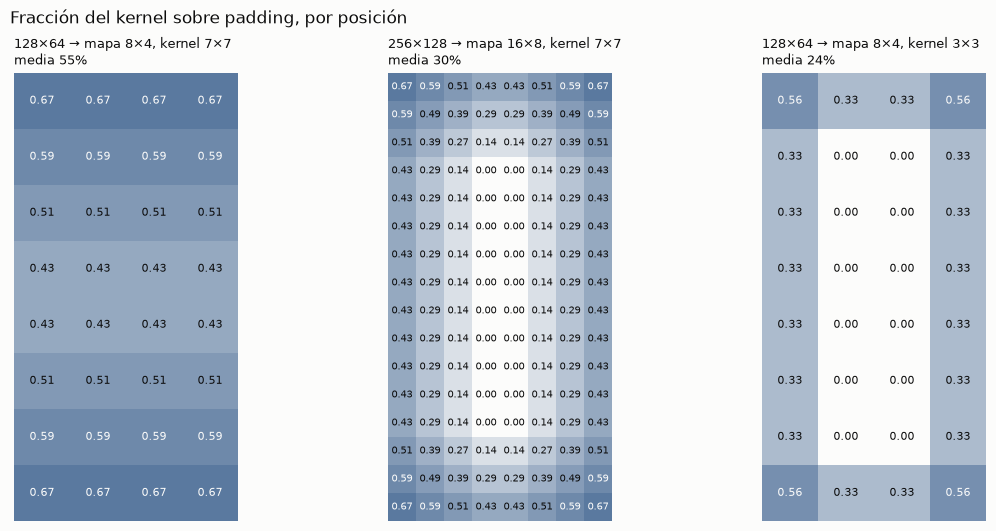

In [4]:
def padding_fraction(height: int, width: int, kernel: int) -> np.ndarray:
    # Celdas válidas del kernel en cada eje, para cada posición.
    half = kernel // 2

    def valid(n):
        i = np.arange(n)
        return np.minimum(i + half, n - 1) - np.maximum(i - half, 0) + 1

    return 1 - np.outer(valid(height), valid(width)) / kernel**2


cases = [
    ("128×64 → mapa 8×4, kernel 7×7", 8, 4, 7),
    ("256×128 → mapa 16×8, kernel 7×7", 16, 8, 7),
    ("128×64 → mapa 8×4, kernel 3×3", 8, 4, 3),
]
fig, axes = plt.subplots(
    1, len(cases), figsize=(10, 5.2), layout="constrained", width_ratios=[4, 8, 4]
)
for ax, (title, h, w, k) in zip(axes, cases, strict=True):
    frac = padding_fraction(h, w, k)
    ax.imshow(frac, cmap=SEQUENTIAL, vmin=0, vmax=1)
    annotate(ax, frac, 1)
    clean(ax)
    ax.set_title(f"{title}\nmedia {frac.mean():.0%}", fontsize=9, loc="left")
fig.suptitle(
    "Fracción del kernel sobre padding, por posición",
    x=0.01,
    ha="left",
    color=INK,
)
plt.show()

En el mapa 8×4 con kernel 7×7, **cada posición ve las 4 columnas completas**:
el kernel cubre todo el ancho. Horizontalmente, lo único que distingue una
columna de otra es dónde cae el padding. En promedio el 55 % del kernel es
padding (contra 30 % en 16×8 y 24 % con kernel 3×3 en 8×4).

## 2. Máscaras de cada run

In [5]:
def sam_mask(
    attention: SpatialAttention, features: torch.Tensor, padding_mode="zeros"
) -> torch.Tensor:
    # Máscara (B, H, W) de la ec. 2, con el padding de ceros del módulo o con
    # otro modo de padding y los mismos pesos.
    pooled = torch.cat(
        [features.mean(1, keepdim=True), features.amax(1, keepdim=True)], dim=1
    )
    half = attention.conv.kernel_size[0] // 2
    if padding_mode != "zeros":
        pooled = F.pad(pooled, (half,) * 4, mode=padding_mode)
        half = 0
    logits = F.conv2d(pooled, attention.conv.weight, padding=half)
    return attention.scale * torch.sigmoid(logits)[:, 0]


def constant_mask(attention: SpatialAttention, features: torch.Tensor):
    # Máscara para un mapa constante con el promedio y el máximo medios del
    # dataset: su estructura espacial viene solo del padding.
    pooled = torch.cat(
        [features.mean(1, keepdim=True), features.amax(1, keepdim=True)], dim=1
    )
    level = pooled.mean((0, 2, 3), keepdim=True)
    constant = level.expand(1, 2, *features.shape[-2:])
    half = attention.conv.kernel_size[0] // 2
    logits = F.conv2d(constant, attention.conv.weight, padding=half)
    return attention.scale * torch.sigmoid(logits)[0, 0]


def correlation(a: torch.Tensor, b: torch.Tensor) -> float:
    a, b = a.flatten() - a.mean(), b.flatten() - b.mean()
    return float((a @ b) / (a.norm() * b.norm()))


def load_model(name: str):
    if name == "init":
        torch.manual_seed(SEED)  # la convolución del SAM usa init aleatoria
        return ReIDModel(weights=ResNet50_Weights.IMAGENET1K_V1), IMAGE_SIZE
    model, _, image_size = load_checkpoint(RUNS_DIR / name / "best.pt")
    return model, image_size


def test_map(name: str) -> str:
    path = RUNS_DIR / name / "best_testing.json"
    if not path.is_file():
        return "—"
    return f"{json.loads(path.read_text())['query']['mAP']:.3f}"


generator = torch.Generator().manual_seed(SEED)
with h5py.File(DATA_DIR / "testing.h5", "r") as file:
    total = file["query/images"].shape[0]
    indices = np.sort(torch.randperm(total, generator=generator)[:NUM_IMAGES])
    images = torch.from_numpy(file["query/images"][indices])

In [6]:
results = {}
for name in RUNS:
    model, image_size = load_model(name)
    model.eval()
    attention = model.capf.attention
    with torch.no_grad():
        features = model.backbone(build_eval_transform(image_size)(images))
        mask = sam_mask(attention, features)
        # La máscara calculada aquí es la que aplica el módulo.
        torch.testing.assert_close(attention(features), features * mask[:, None])
        results[name] = {
            "image_size": image_size,
            "scale": attention.scale,
            "mask": mask,
            "constant": constant_mask(attention, features),
            "replicate": sam_mask(attention, features, "replicate"),
        }
    del model, features

In [7]:
def centre_border(mask: torch.Tensor) -> float:
    # Columnas centrales (sin filas de los extremos) contra columnas laterales.
    _, h, w = mask.shape
    q = w // 4
    centre = mask[:, h // 8 : h - h // 8, q : w - q].mean()
    border = torch.cat([mask[:, :, :q], mask[:, :, w - q :]], dim=2).mean()
    return float(centre / border)


def positional_share(mask: torch.Tensor) -> float:
    # Varianza total = varianza de la máscara media entre posiciones
    # + varianza media entre imágenes en cada posición.
    between_positions = mask.mean(0).var(unbiased=False)
    within_positions = mask.var(0, unbiased=False).mean()
    return float(between_positions / (between_positions + within_positions))


rows = []
for name, r in results.items():
    mask, scale = r["mask"], r["scale"]
    saturated = ((mask < 0.05 * scale) | (mask > 0.95 * scale)).float().mean()
    r["corr_constant"] = correlation(mask.mean(0), r["constant"])
    r["positional"] = positional_share(mask)
    r["replicate_change"] = float((r["replicate"] - mask).abs().mean() / mask.mean())
    h, w = mask.shape[-2:]
    rows.append(
        {
            "run": name,
            "entrada": "{}×{}".format(*r["image_size"]),
            "mapa": f"{h}×{w}",
            "rango": f"(0, {scale:g})",
            "media": f"{mask.mean():.2f}",
            "saturada": f"{saturated:.0%}",
            "centro/borde": f"{centre_border(mask):.2f}",
            "corr. con entrada constante": f"{r['corr_constant']:.2f}",
            "varianza por posición": f"{r['positional']:.0%}",
            "cambio con replicate": f"{r['replicate_change']:.0%}",
            "mAP test": test_map(name),
        }
    )
display(Markdown(markdown_table(rows)))

| run | entrada | mapa | rango | media | saturada | centro/borde | corr. con entrada constante | varianza por posición | cambio con replicate | mAP test |
|---|---|---|---|---|---|---|---|---|---|---|
| init | 128×64 | 8×4 | (0, 1) | 0.19 | 35% | 0.24 | 0.99 | 91% | 76% | — |
| ahcl | 128×64 | 8×4 | (0, 1) | 0.23 | 0% | 1.28 | 0.86 | 81% | 75% | 0.060 |
| ahcl_256 | 256×128 | 16×8 | (0, 1) | 0.85 | 28% | 1.28 | 0.94 | 97% | 15% | 0.026 |
| abl_no_se | 128×64 | 8×4 | (0, 1) | 0.25 | 12% | 1.52 | 0.82 | 93% | 50% | 0.052 |
| capf_fix_bal | 128×64 | 8×4 | (0, 1) | 0.29 | 1% | 1.37 | 0.92 | 89% | 57% | 0.066 |
| capf_fix_id | 128×64 | 8×4 | (0, 2) | 0.67 | 0% | 1.15 | 0.57 | 62% | 40% | 0.116 |
| capf_fix | 128×64 | 8×4 | (0, 2) | 0.62 | 4% | 1.30 | 0.53 | 83% | 47% | 0.100 |
| capf_fix_a1 | 128×64 | 8×4 | (0, 2) | 0.50 | 2% | 1.31 | 0.28 | 72% | 57% | 0.181 |

- **saturada**: celdas con máscara por debajo del 5 % o por encima del 95 % de
  su rango (ahí la sigmoide casi no deja pasar gradiente).
- **centro/borde**: máscara media en las columnas centrales sobre la de las
  columnas laterales; > 1 resalta el centro, donde suele estar la persona.
- **corr. con entrada constante**: correlación entre la máscara media real y
  la que produce un mapa constante (solo padding). Cerca de 1: el patrón medio
  de la máscara lo explica el padding.
- **varianza por posición**: fracción de la varianza de la máscara que es un
  patrón fijo por posición, igual para todas las imágenes.
- **cambio con replicate**: cambio medio de la máscara al usar padding
  `replicate` en vez de ceros, relativo a la máscara media.

## 3. Máscara media real contra máscara con entrada constante

Izquierda: máscara media sobre las queries. Derecha: la misma convolución sobre
un mapa constante. Si se parecen, el patrón de la máscara lo pone el padding y
no el contenido de las imágenes. Cada fila usa la escala de su máscara.

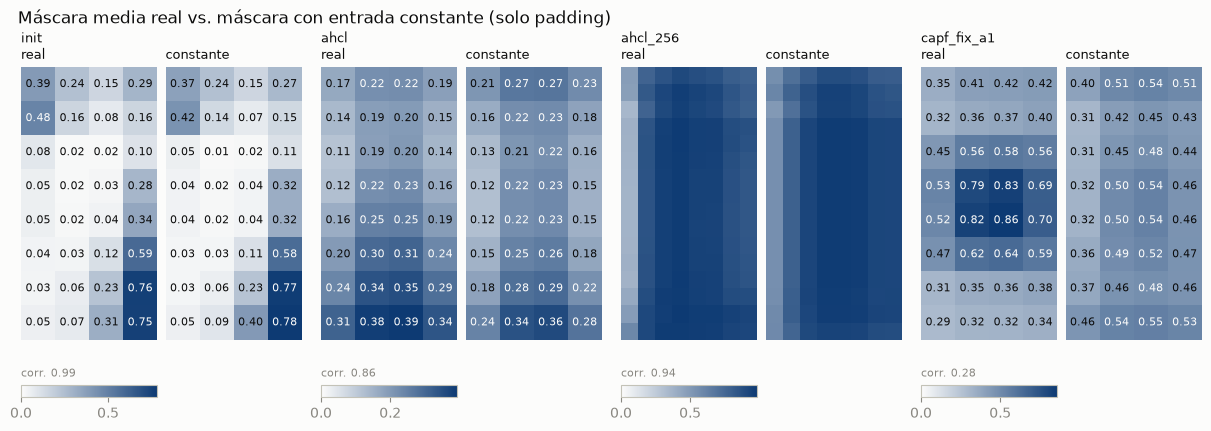

In [8]:
fig, axes = plt.subplots(
    2,
    2 * len(EXAMPLE_RUNS),
    figsize=(12, 4.2),
    layout="constrained",
    height_ratios=[1, 0.04],
)
for col, name in enumerate(EXAMPLE_RUNS):
    r = results[name]
    panels = [("real", r["mask"].mean(0)), ("constante", r["constant"])]
    vmax = max(float(p.max()) for _, p in panels)
    for offset, (label, values) in enumerate(panels):
        ax = axes[0, 2 * col + offset]
        image = ax.imshow(values.numpy(), cmap=SEQUENTIAL, vmin=0, vmax=vmax)
        if values.shape[0] <= 8:
            annotate(ax, values.numpy(), vmax)
        clean(ax)
        title = f"{name}\n{label}" if offset == 0 else f"\n{label}"
        ax.set_title(title, fontsize=9, loc="left")
    cax = axes[1, 2 * col : 2 * col + 2]
    for ax in cax[1:]:
        ax.remove()
    fig.colorbar(image, cax=cax[0], orientation="horizontal")
    cax[0].set_title(
        f"corr. {r['corr_constant']:.2f}", fontsize=8, loc="left", color=MUTED
    )
fig.suptitle(
    "Máscara media real vs. máscara con entrada constante (solo padding)",
    x=0.01,
    ha="left",
    color=INK,
)
plt.show()

## 4. ¿Posición o contenido?

Las tres medidas de la tabla, por run. Las barras más largas indican una
máscara más dependiente de la posición y del padding.

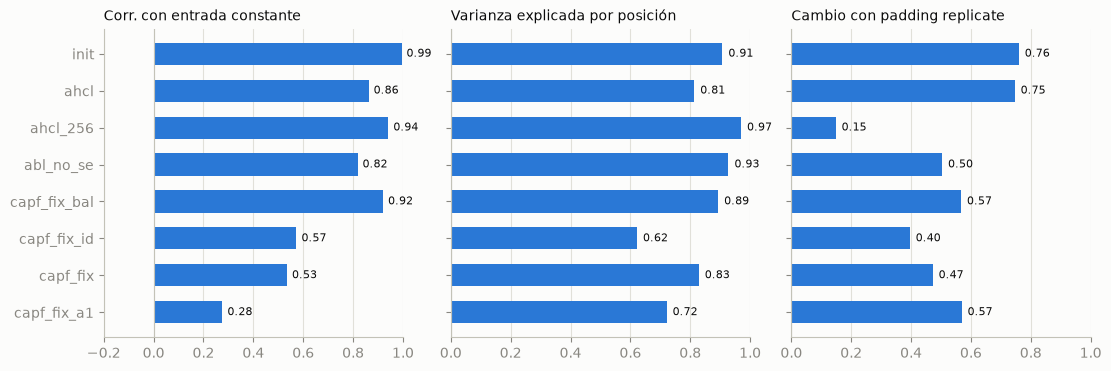

In [9]:
measures = [
    ("Corr. con entrada constante", "corr_constant", (-0.2, 1.0)),
    ("Varianza explicada por posición", "positional", (0, 1.0)),
    ("Cambio con padding replicate", "replicate_change", (0, 1.0)),
]
names = list(results)
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6), layout="constrained", sharey=True)
for ax, (title, key, limits) in zip(axes, measures, strict=True):
    values = [results[name][key] for name in names]
    ax.barh(names, values, color=SERIES[0], height=0.6)
    for y, v in enumerate(values):
        ax.text(v + 0.02, y, f"{v:.2f}", va="center", fontsize=8, color=INK)
    ax.set_xlim(*limits)
    ax.set_title(title, fontsize=10, loc="left")
    ax.grid(axis="y", visible=False)
    ax.axvline(0, color="#c3c2b7", linewidth=0.8)
axes[0].invert_yaxis()
plt.show()

## 5. Ejemplos

Máscara de cada run sobre las mismas queries (celdas del mapa sin interpolar,
para que se vea su tamaño real). Oscuro = máscara alta.

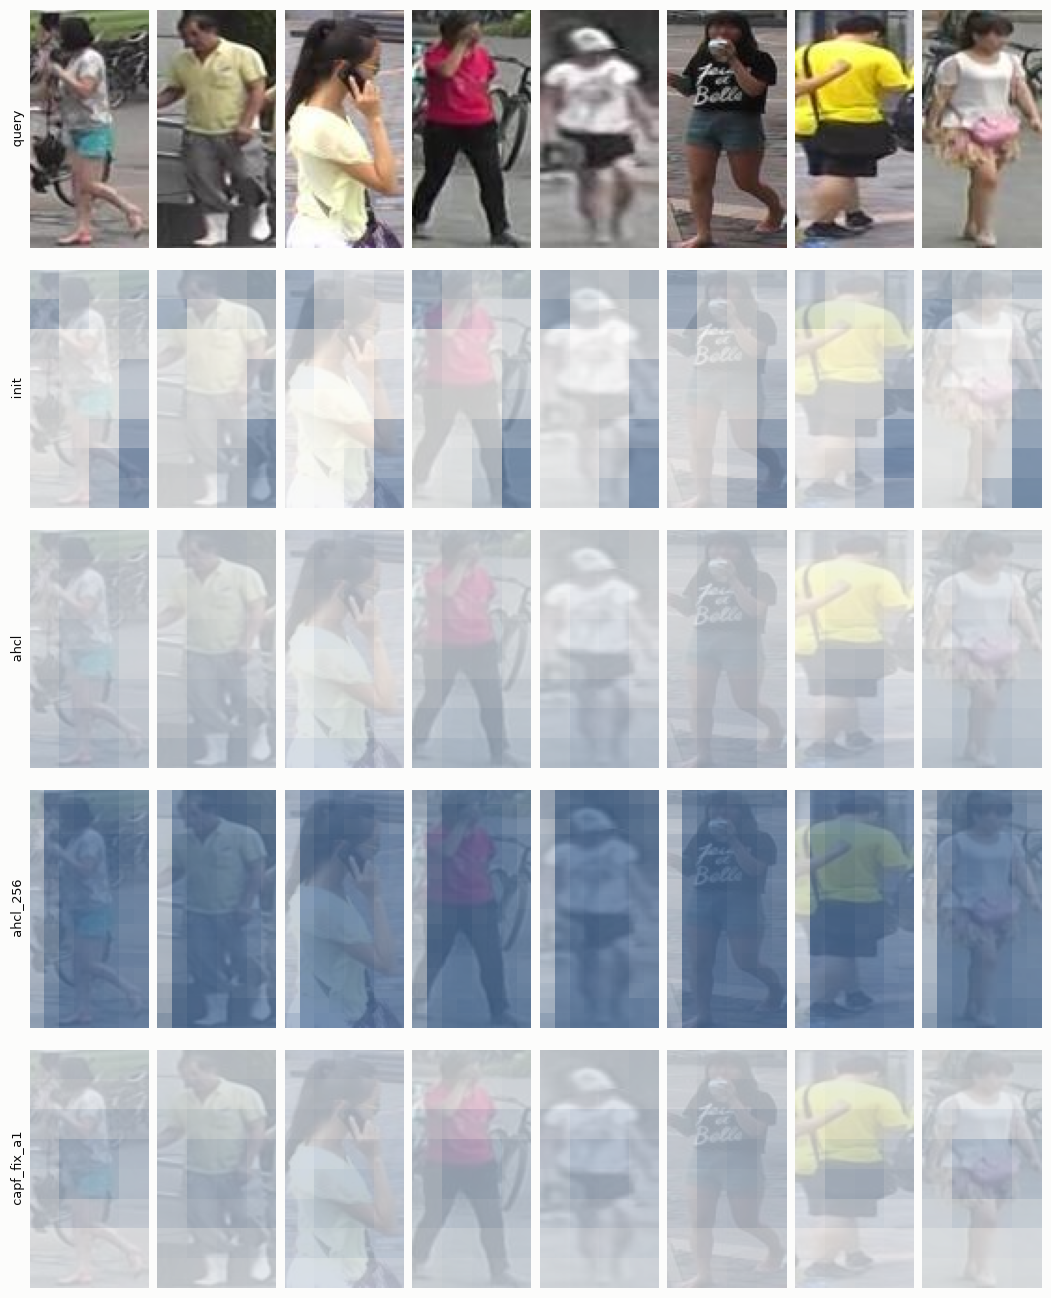

In [10]:
EXAMPLES = 8
fig, axes = plt.subplots(
    len(EXAMPLE_RUNS) + 1,
    EXAMPLES,
    figsize=(1.3 * EXAMPLES, 2.6 * (len(EXAMPLE_RUNS) + 1)),
    layout="constrained",
)
for j in range(EXAMPLES):
    picture = images[j].permute(1, 2, 0).numpy()
    axes[0, j].imshow(picture)
    for i, name in enumerate(EXAMPLE_RUNS, start=1):
        r = results[name]
        ax = axes[i, j]
        ax.imshow(picture, alpha=0.5)
        mask = r["mask"][j].numpy()
        h, w = picture.shape[:2]
        ax.imshow(
            mask,
            cmap=SEQUENTIAL,
            vmin=0,
            vmax=r["scale"],
            alpha=0.6,
            extent=(-0.5, w - 0.5, h - 0.5, -0.5),
            interpolation="nearest",
        )
for ax in axes.flat:
    clean(ax)
for i, label in enumerate(["query", *EXAMPLE_RUNS]):
    axes[i, 0].set_ylabel(label, fontsize=9, color=INK)
    axes[i, 0].yaxis.set_visible(True)
plt.show()

## 6. Conclusión

Con 256 queries de test y semilla 0:

- **Con 8×4, el padding pesa mucho en la máscara.** Más de la mitad del kernel
  cae sobre padding y el kernel cubre todo el ancho. Al cambiar solo el modo de
  padding, la máscara de todos los runs 8×4 cambia entre 40 % y 76 %; en el run
  16×8 (`ahcl_256`) cambia 15 %.
- **Sin `identity_attention`, la máscara es casi un patrón fijo puesto por el
  padding.** En `init`, `ahcl`, `abl_no_se` y `capf_fix_bal`, la máscara media
  correlaciona 0.82–0.99 con la que da una entrada constante, y el 81–93 % de
  su varianza es por posición. No separa a la persona del fondo: en `ahcl`
  multiplica casi todo el mapa por ~0.2, con un gradiente de arriba hacia
  abajo, y en `init` deja pasar sobre todo una columna lateral (centro/borde
  0.24).
- **Agrandar la entrada no lo arregla.** En `ahcl_256` (mapa 16×8) la máscara
  es todavía más fija (97 % de la varianza por posición, corr. 0.94 con la
  entrada constante): ~0.9 en casi todo el mapa y ~0.4 en la columna
  izquierda, sin relación con dónde está la persona.
- **Con `identity_attention` la máscara deja de ser un efecto del padding.**
  En `capf_fix_a1` la correlación con la entrada constante baja a 0.28 y la
  máscara resalta las filas del torso (~0.8) frente a cabeza y piernas (~0.3).
  Sigue siendo sobre todo posicional (72 %): aprende un "prior" de dónde suele
  estar el torso en el recorte, más que una máscara de persona por imagen.

En resumen, el mapa 8×4 hace que la convolución 7×7 dependa mucho del padding,
pero el problema de fondo es otro: en ningún run la máscara sigue a la persona
imagen por imagen.